<a href="https://colab.research.google.com/github/ravi-0552/Python_CourseEndProject/blob/main/HVAC_Analysisimport_pandas_as_pd_import_numpy_as_np_import_matplotlib_pyplot_as_plt_import_seaborn_as_sns_from_pathlib_import_Path.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

Saving RTU.csv to RTU.csv


In [5]:
import io

filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (30240, 69)


,Timestamp,RTU: Supply Air Temperature,RTU: Return Air Temperature,RTU: Supply Air Fan Status,RTU: Circuit 1 Discharge Temperature,RTU: Circuit 1 Condenser Outlet Temperature,RTU: Circuit 1 Suction Temperature,RTU: Circuit 2 Discharge Temperature,RTU: Circuit 2 Condenser Outlet Temperature,RTU: Circuit 2 Suction Temperature,...,VAV Box: Room 103 Air Temperature,VAV Box: Room 104 Air Temperature,VAV Box: Room 105 Air Temperature,VAV Box: Room 106 Air Temperature,VAV Box: Room 202 Air Temperature,VAV Box: Room 203 Air Temperature,VAV Box: Room 204 Air Temperature,VAV Box: Room 205 Air Temperature,VAV Box: Room 206 Air Temperature,Fault Detection Ground Truth
0,8/27/2017 0:00,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,8/27/2017 0:01,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,8/27/2017 0:02,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,8/27/2017 0:03,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,8/27/2017 0:04,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1


In [6]:
print("COLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES AND NON-NULL COUNTS:")
df.info()

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

print("\nSTATISTICAL SUMMARY:")
display(df.describe(include="all").T)

COLUMN NAMES:
['Timestamp', 'RTU: Supply Air Temperature', 'RTU: Return Air Temperature', 'RTU: Supply Air Fan Status', 'RTU: Circuit 1 Discharge Temperature', 'RTU: Circuit 1 Condenser Outlet Temperature', 'RTU: Circuit 1 Suction Temperature', 'RTU: Circuit 2 Discharge Temperature', 'RTU: Circuit 2 Condenser Outlet Temperature', 'RTU: Circuit 2 Suction Temperature', 'RTU: Circuit 1 Discharge Pressure', 'RTU: Circuit 1 Condenser Outlet Pressure', 'RTU: Circuit 1 Suction Pressure', 'RTU: Circuit 2 Discharge Pressure', 'RTU: Circuit 2 Condenser Outlet Pressure', 'RTU: Circuit 2 Suction Pressure', 'RTU: Supply Air Volumetric Flow Rate', 'RTU: Electricity', 'RTU: Natural Gas', 'Occupancy Mode Indicator', 'Terminal: Room 102 Air Humidity', 'Terminal: Room 103 Air Humidity', 'Terminal: Room 104 Air Humidity', 'Terminal: Room 105 Air Humidity', 'Terminal: Room 106 Air Humidity', 'Terminal: Room 202 Air Humidity', 'Terminal: Room 203 Air Humidity', 'Terminal: Room 204 Air Humidity', 'Terminal:

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Timestamp,30240,30240,2/18/2018 23:43,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RTU: Supply Air Temperature,20156.0,NaN,NaN,NaN,56.057618,5.072376,31.64,51.8275,55.14,60.07,82.5
RTU: Return Air Temperature,20156.0,NaN,NaN,NaN,68.944294,1.717517,55.5,68.25,68.65,69.57,76.24
RTU: Supply Air Fan Status,30240.0,NaN,NaN,NaN,0.665675,0.471762,0.0,0.0,1.0,1.0,1.0
RTU: Circuit 1 Discharge Temperature,15028.0,NaN,NaN,NaN,112.526113,16.209487,27.05,102.8,109.8,116.7,172.7
...,...,...,...,...,...,...,...,...,...,...,...
VAV Box: Room 203 Air Temperature,20156.0,NaN,NaN,NaN,63.838111,6.665194,47.25,58.53,63.62,68.16,94.3
VAV Box: Room 204 Air Temperature,20156.0,NaN,NaN,NaN,71.6611,7.985146,46.49,66.57,71.36,76.28,96.9
VAV Box: Room 205 Air Temperature,20156.0,NaN,NaN,NaN,69.549182,10.642896,46.39,60.61,68.86,76.86,99.2
VAV Box: Room 206 Air Temperature,20156.0,NaN,NaN,NaN,66.219404,8.384326,50.1,59.23,66.01,71.01,90.8


In [7]:
# Standardize column names
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(" ", "_", regex=False)
)

# Remove duplicate records
df = df.drop_duplicates().copy()

print("Dataset cleaned.")
print("Rows and columns:", df.shape)

display(df.head())

Dataset cleaned.
Rows and columns: (30240, 69)


,Timestamp,RTU:_Supply_Air_Temperature,RTU:_Return_Air_Temperature,RTU:_Supply_Air_Fan_Status,RTU:_Circuit_1_Discharge_Temperature,RTU:_Circuit_1_Condenser_Outlet_Temperature,RTU:_Circuit_1_Suction_Temperature,RTU:_Circuit_2_Discharge_Temperature,RTU:_Circuit_2_Condenser_Outlet_Temperature,RTU:_Circuit_2_Suction_Temperature,...,VAV_Box:_Room_103_Air_Temperature,VAV_Box:_Room_104_Air_Temperature,VAV_Box:_Room_105_Air_Temperature,VAV_Box:_Room_106_Air_Temperature,VAV_Box:_Room_202_Air_Temperature,VAV_Box:_Room_203_Air_Temperature,VAV_Box:_Room_204_Air_Temperature,VAV_Box:_Room_205_Air_Temperature,VAV_Box:_Room_206_Air_Temperature,Fault_Detection_Ground_Truth
0,8/27/2017 0:00,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,8/27/2017 0:01,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,8/27/2017 0:02,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,8/27/2017 0:03,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,8/27/2017 0:04,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1


In [8]:
print("Available columns in RTU.csv:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Available columns in RTU.csv:

1. Timestamp
2. RTU:_Supply_Air_Temperature
3. RTU:_Return_Air_Temperature
4. RTU:_Supply_Air_Fan_Status
5. RTU:_Circuit_1_Discharge_Temperature
6. RTU:_Circuit_1_Condenser_Outlet_Temperature
7. RTU:_Circuit_1_Suction_Temperature
8. RTU:_Circuit_2_Discharge_Temperature
9. RTU:_Circuit_2_Condenser_Outlet_Temperature
10. RTU:_Circuit_2_Suction_Temperature
11. RTU:_Circuit_1_Discharge_Pressure
12. RTU:_Circuit_1_Condenser_Outlet_Pressure
13. RTU:_Circuit_1_Suction_Pressure
14. RTU:_Circuit_2_Discharge_Pressure
15. RTU:_Circuit_2_Condenser_Outlet_Pressure
16. RTU:_Circuit_2_Suction_Pressure
17. RTU:_Supply_Air_Volumetric_Flow_Rate
18. RTU:_Electricity
19. RTU:_Natural_Gas
20. Occupancy_Mode_Indicator
21. Terminal:_Room_102_Air_Humidity
22. Terminal:_Room_103_Air_Humidity
23. Terminal:_Room_104_Air_Humidity
24. Terminal:_Room_105_Air_Humidity
25. Terminal:_Room_106_Air_Humidity
26. Terminal:_Room_202_Air_Humidity
27. Terminal:_Room_203_Air_Humidity
28. Termina

In [9]:
# Convert timestamp to datetime
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

# Sort records chronologically
df = df.sort_values("Timestamp").reset_index(drop=True)

# Convert measurement columns to numeric
for col in df.columns:
    if col != "Timestamp":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows without timestamps
df = df.dropna(subset=["Timestamp"]).copy()

print("Data cleaning completed!")
print("Dataset shape:", df.shape)
print("Date range:", df["Timestamp"].min(), "to", df["Timestamp"].max())
print("\nMissing values in important columns:")
print(df[[
    "RTU:_Electricity",
    "RTU:_Natural_Gas",
    "HVAC_System:_Electricity",
    "Terminal:_Room_Air_Temperature_Cooling_Setpoint",
    "Terminal:_Room_Air_Temperature_Heating_Setpoint"
]].isnull().sum())

Data cleaning completed!
Dataset shape: (30240, 69)
Date range: 2017-08-27 00:00:00 to 2018-02-18 23:59:00

Missing values in important columns:
RTU:_Electricity                                   0
RTU:_Natural_Gas                                   0
HVAC_System:_Electricity                           0
Terminal:_Room_Air_Temperature_Cooling_Setpoint    0
Terminal:_Room_Air_Temperature_Heating_Setpoint    0
dtype: int64


In [10]:
# Identify room temperature columns
room_temp_cols = [
    col for col in df.columns
    if col.startswith("Terminal:_Room_")
    and col.endswith("_Air_Temperature")
]

# Calculate average temperature across rooms
df["Average_Indoor_Temperature"] = df[room_temp_cols].mean(axis=1)

# Get heating and cooling setpoints
heating_col = "Terminal:_Room_Air_Temperature_Heating_Setpoint"
cooling_col = "Terminal:_Room_Air_Temperature_Cooling_Setpoint"

df["Heating_Setpoint"] = df[heating_col]
df["Cooling_Setpoint"] = df[cooling_col]

# Calculate deviation from the nearest applicable comfort boundary
df["Comfort_Deviation"] = np.maximum(
    df["Heating_Setpoint"] - df["Average_Indoor_Temperature"],
    df["Average_Indoor_Temperature"] - df["Cooling_Setpoint"]
).clip(lower=0)

# Identify observations outside the setpoint range
df["Outside_Comfort_Range"] = (
    (df["Average_Indoor_Temperature"] < df["Heating_Setpoint"]) |
    (df["Average_Indoor_Temperature"] > df["Cooling_Setpoint"])
)

print("Average indoor temperature:",
      round(df["Average_Indoor_Temperature"].mean(), 2))

print("Observations outside comfort range:",
      int(df["Outside_Comfort_Range"].sum()))

print("Percentage outside comfort range:",
      round(df["Outside_Comfort_Range"].mean() * 100, 2), "%")

display(df[[
    "Timestamp",
    "Average_Indoor_Temperature",
    "Heating_Setpoint",
    "Cooling_Setpoint",
    "Comfort_Deviation",
    "Outside_Comfort_Range"
]].head())

Average indoor temperature: 70.36
Observations outside comfort range: 2848
Percentage outside comfort range: 9.42 %


,Timestamp,Average_Indoor_Temperature,Heating_Setpoint,Cooling_Setpoint,Comfort_Deviation,Outside_Comfort_Range
0,2017-08-27 00:00:00,73.226,60.0,80.0,0.0,False
1,2017-08-27 00:01:00,73.226,60.0,80.0,0.0,False
2,2017-08-27 00:02:00,73.264,60.0,80.0,0.0,False
3,2017-08-27 00:03:00,73.268,60.0,80.0,0.0,False
4,2017-08-27 00:04:00,73.238,60.0,80.0,0.0,False


In [11]:
energy_cols = [
    "RTU:_Electricity",
    "RTU:_Natural_Gas",
    "HVAC_System:_Electricity",
    "Lighting_System:_Electricity",
    "RTU:_Fan_Electricity"
]

print("Energy measurement summary:")
display(df[energy_cols].describe().T)

# Daily aggregation for initial analysis
df["Date"] = df["Timestamp"].dt.date

daily_energy = df.groupby("Date")[energy_cols].sum(min_count=1)

print("Daily aggregated measurements:")
display(daily_energy.head())

Energy measurement summary:


,count,mean,std,min,25%,50%,75%,max
RTU:_Electricity,30240.0,57.485500,56.066798,2.07747,2.30830,31.392880,102.026900,316.929600
RTU:_Natural_Gas,30240.0,0.001175,0.062316,0.00000,0.00000,0.000000,0.000000,4.230452
HVAC_System:_Electricity,30240.0,188.514477,160.866347,3.37014,3.78565,192.028240,312.662247,618.475090
Lighting_System:_Electricity,30240.0,26.189124,13.678522,8.58884,10.10091,26.851015,40.326880,42.416420
RTU:_Fan_Electricity,30240.0,19.276714,13.823483,0.27702,0.32319,27.886680,28.394550,36.843660


Daily aggregated measurements:


,RTU:_Electricity,RTU:_Natural_Gas,HVAC_System:_Electricity,Lighting_System:_Electricity,RTU:_Fan_Electricity
Date,,,,,
2017-08-27,145152.824150,0.0,181375.487053,36328.511632,32627.73879
2017-08-28,2.077470,0.0,3.474020,10.555270,0.32319
2017-08-29,177381.998869,0.0,217508.144934,36323.338134,32600.77551
2017-09-01,117486.694470,0.0,187501.993575,36381.153593,32517.90036
2017-11-30,72250.018770,0.0,244538.170699,36719.511827,25397.33211


In [12]:
status_cols = [
    "RTU:_Supply_Air_Fan_Status",
    "RTU:_Compressor_1_On/Off_Status",
    "RTU:_Compressor_2_On/Off_Status"
]

print("HVAC operating status summary:")
display(df[status_cols].describe().T)

for col in status_cols:
    print(f"\n{col} — value counts:")
    print(df[col].value_counts(dropna=False).head(10))

HVAC operating status summary:


,count,mean,std,min,25%,50%,75%,max
RTU:_Supply_Air_Fan_Status,30240.0,0.665675,0.471762,0.0,0.0,1.0,1.0,1.0
RTU:_Compressor_1_On/Off_Status,30240.0,0.491468,0.499935,0.0,0.0,0.0,1.0,1.0
RTU:_Compressor_2_On/Off_Status,30240.0,0.030622,0.172293,0.0,0.0,0.0,0.0,1.0



RTU:_Supply_Air_Fan_Status — value counts:
RTU:_Supply_Air_Fan_Status
1    20130
0    10110
Name: count, dtype: int64

RTU:_Compressor_1_On/Off_Status — value counts:
RTU:_Compressor_1_On/Off_Status
0    15378
1    14862
Name: count, dtype: int64

RTU:_Compressor_2_On/Off_Status — value counts:
RTU:_Compressor_2_On/Off_Status
0    29314
1      926
Name: count, dtype: int64


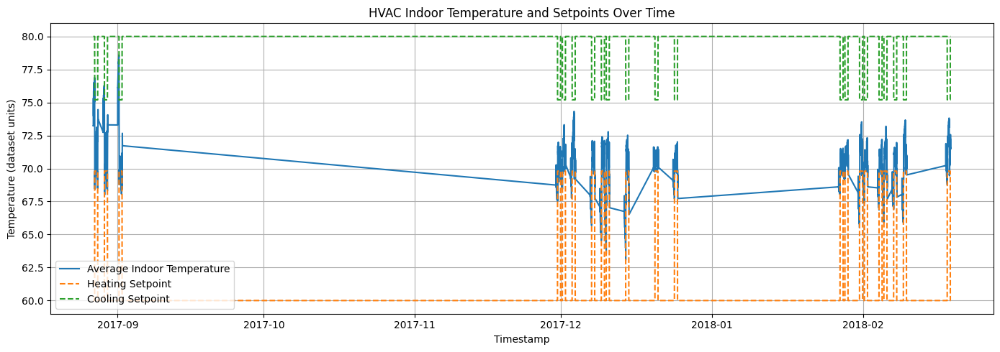

In [13]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Timestamp"],
    df["Average_Indoor_Temperature"],
    label="Average Indoor Temperature"
)

plt.plot(
    df["Timestamp"],
    df["Heating_Setpoint"],
    linestyle="--",
    label="Heating Setpoint"
)

plt.plot(
    df["Timestamp"],
    df["Cooling_Setpoint"],
    linestyle="--",
    label="Cooling Setpoint"
)

plt.title("HVAC Indoor Temperature and Setpoints Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature (dataset units)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

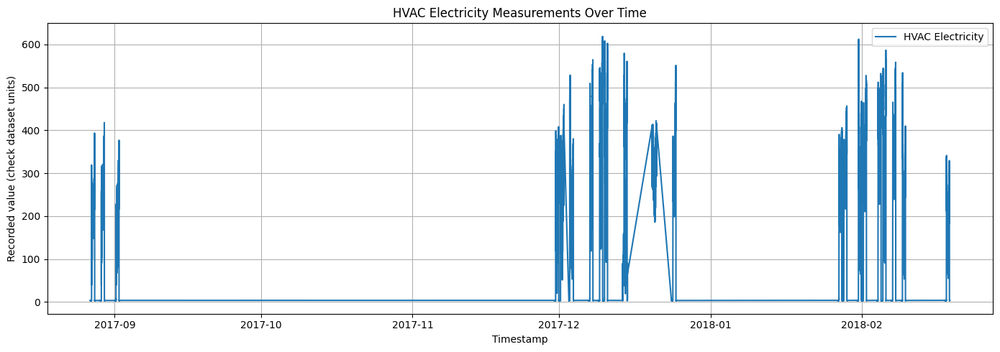

In [14]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Timestamp"],
    df["HVAC_System:_Electricity"],
    label="HVAC Electricity"
)

plt.title("HVAC Electricity Measurements Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Recorded value (check dataset units)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

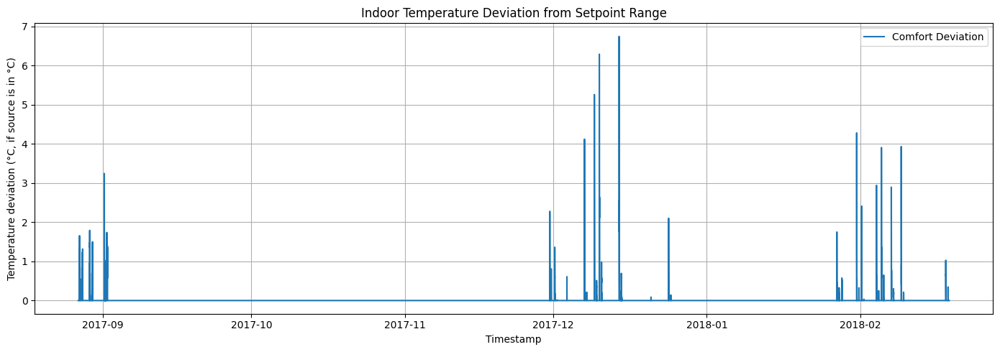

In [15]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Timestamp"],
    df["Comfort_Deviation"],
    label="Comfort Deviation"
)

plt.title("Indoor Temperature Deviation from Setpoint Range")
plt.xlabel("Timestamp")
plt.ylabel("Temperature deviation (°C, if source is in °C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

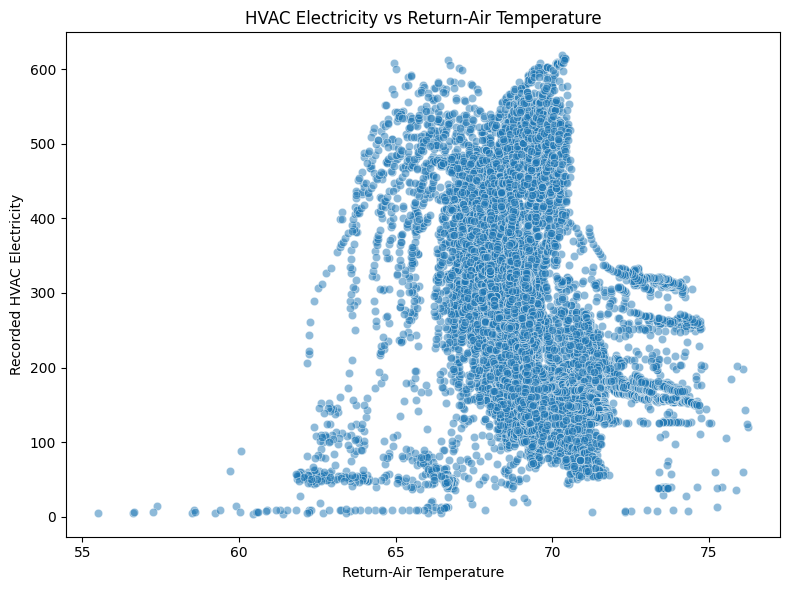

In [16]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="RTU:_Return_Air_Temperature",
    y="HVAC_System:_Electricity",
    alpha=0.5
)

plt.title("HVAC Electricity vs Return-Air Temperature")
plt.xlabel("Return-Air Temperature")
plt.ylabel("Recorded HVAC Electricity")
plt.tight_layout()
plt.show()

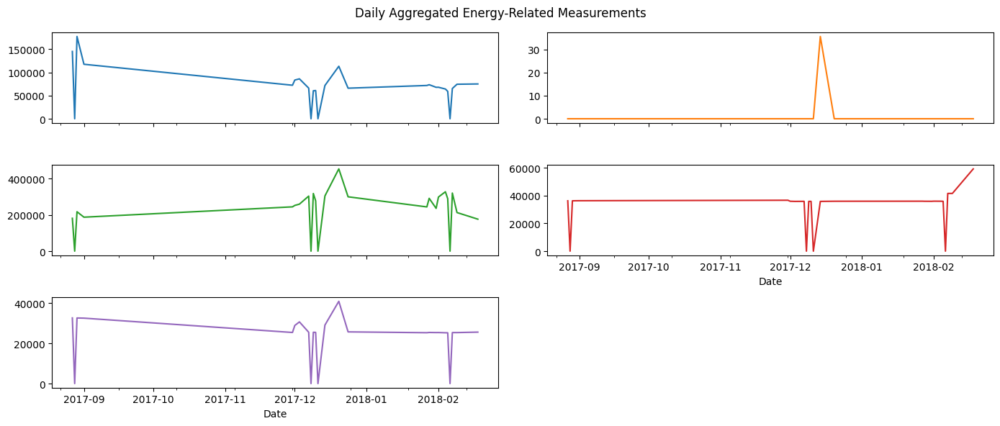

In [17]:
daily_energy.plot(
    figsize=(14, 6),
    subplots=True,
    layout=(3, 2),
    title="Daily Aggregated Energy-Related Measurements",
    legend=False
)

plt.tight_layout()
plt.show()

In [18]:
summary = {
    "Total Records": len(df),
    "Average Indoor Temperature": df["Average_Indoor_Temperature"].mean(),
    "Minimum Indoor Temperature": df["Average_Indoor_Temperature"].min(),
    "Maximum Indoor Temperature": df["Average_Indoor_Temperature"].max(),
    "Observations Outside Setpoint Range": int(df["Outside_Comfort_Range"].sum()),
    "Percentage Outside Setpoint Range": df["Outside_Comfort_Range"].mean() * 100,
    "Average HVAC Electricity Reading": df["HVAC_System:_Electricity"].mean(),
    "Average Return-Air Temperature": df["RTU:_Return_Air_Temperature"].mean()
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

display(summary_df.round(2))

,Metric,Value
0,Total Records,30240.00
1,Average Indoor Temperature,70.36
2,Minimum Indoor Temperature,63.06
3,Maximum Indoor Temperature,78.60
4,Observations Outside Setpoint Range,2848.00
5,Percentage Outside Setpoint Range,9.42
6,Average HVAC Electricity Reading,188.51
7,Average Return-Air Temperature,68.94


In [19]:
df.to_csv("cleaned_hvac_data.csv", index=False)

daily_energy.to_csv("daily_energy_measurements.csv")

summary_df.to_csv("hvac_summary_report.csv", index=False)

print("Project output files saved successfully!")

Project output files saved successfully!


In [22]:
from google.colab import files

files.download("cleaned_hvac_data.csv")
files.download("daily_energy_measurements.csv")
files.download("hvac_summary_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
print("Timestamp sampling intervals:")
print(df["Timestamp"].diff().value_counts().head())

print("\nEnergy column samples:")
display(df[energy_cols].head(10))

print("\nHVAC status values:")
for col in status_cols:
    print(col, ":", sorted(df[col].dropna().unique().tolist())[:20])

Timestamp sampling intervals:
Timestamp
0 days 00:01:00     30224
1 days 00:01:00         5
2 days 00:01:00         3
3 days 00:01:00         3
89 days 00:01:00        1
Name: count, dtype: int64

Energy column samples:


,RTU:_Electricity,RTU:_Natural_Gas,HVAC_System:_Electricity,Lighting_System:_Electricity,RTU:_Fan_Electricity
0,2.07747,0.0,3.50865,10.57066,0.32319
1,2.30830,0.0,3.70485,10.57066,0.32319
2,2.07747,0.0,3.54327,10.55142,0.32319
3,2.07747,0.0,3.42785,10.57451,0.27702
4,2.07747,0.0,3.47402,10.57066,0.32319
5,2.07747,0.0,3.63561,10.55527,0.32319
6,2.30830,0.0,3.70485,10.57066,0.27702
7,2.07747,0.0,3.48556,10.58605,0.32319
8,2.07747,0.0,3.48556,10.55527,0.32319
9,2.07747,0.0,3.50865,10.56681,0.32319



HVAC status values:
RTU:_Supply_Air_Fan_Status : [0, 1]
RTU:_Compressor_1_On/Off_Status : [0, 1]
RTU:_Compressor_2_On/Off_Status : [0, 1]


In [24]:
# Calculate time differences between consecutive records
time_diff = df["Timestamp"].diff()

# Keep only intervals of exactly one minute
valid_interval = time_diff == pd.Timedelta(minutes=1)

status_cols = [
    "RTU:_Supply_Air_Fan_Status",
    "RTU:_Compressor_1_On/Off_Status",
    "RTU:_Compressor_2_On/Off_Status"
]

print("Estimated operating time from valid one-minute intervals:\n")

for col in status_cols:
    # Count a minute only when the current and previous statuses are both known
    valid_status = (
        valid_interval
        & df[col].notna()
        & df[col].shift(1).notna()
    )

    # Count the interval when the previous reading indicates ON
    operating_minutes = (
        (df[col].shift(1) == 1) & valid_status
    ).sum()

    print(f"{col}: {operating_minutes} minutes")
    print(f"Estimated hours: {operating_minutes / 60:.2f}\n")

Estimated operating time from valid one-minute intervals:

RTU:_Supply_Air_Fan_Status: 20127 minutes
Estimated hours: 335.45

RTU:_Compressor_1_On/Off_Status: 14860 minutes
Estimated hours: 247.67

RTU:_Compressor_2_On/Off_Status: 926 minutes
Estimated hours: 15.43



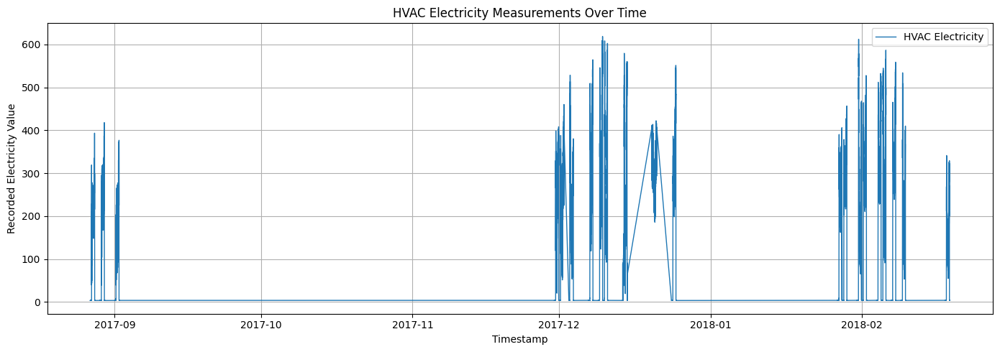

In [25]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Timestamp"],
    df["HVAC_System:_Electricity"],
    label="HVAC Electricity",
    linewidth=1
)

plt.title("HVAC Electricity Measurements Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Recorded Electricity Value")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
room_comfort_results = []

for col in room_temp_cols:
    room_temp = df[col]

    outside = (
        (room_temp < df["Heating_Setpoint"]) |
        (room_temp > df["Cooling_Setpoint"])
    )

    valid = (
        room_temp.notna()
        & df["Heating_Setpoint"].notna()
        & df["Cooling_Setpoint"].notna()
    )

    room_comfort_results.append({
        "Room": col.replace("Terminal:_", ""),
        "Average Temperature": room_temp.mean(),
        "Outside Comfort Observations": int(outside[valid].sum()),
        "Valid Observations": int(valid.sum()),
        "Outside Comfort (%)": (
            outside[valid].mean() * 100 if valid.sum() > 0 else np.nan
        )
    })

room_comfort_df = pd.DataFrame(room_comfort_results)

display(
    room_comfort_df.sort_values(
        "Outside Comfort (%)",
        ascending=False
    ).round(2)
)

,Room,Average Temperature,Outside Comfort Observations,Valid Observations,Outside Comfort (%)
6,Room_203_Air_Temperature,68.39,18025,30240,59.61
5,Room_202_Air_Temperature,70.29,10925,30240,36.13
0,Room_102_Air_Temperature,69.61,6225,30240,20.59
2,Room_104_Air_Temperature,69.36,4777,30240,15.80
8,Room_205_Air_Temperature,71.39,4285,30240,14.17
3,Room_105_Air_Temperature,70.59,3255,30240,10.76
4,Room_106_Air_Temperature,70.40,3022,30240,9.99
9,Room_206_Air_Temperature,71.02,2754,30240,9.11
7,Room_204_Air_Temperature,70.29,2246,30240,7.43
1,Room_103_Air_Temperature,72.23,1805,30240,5.97


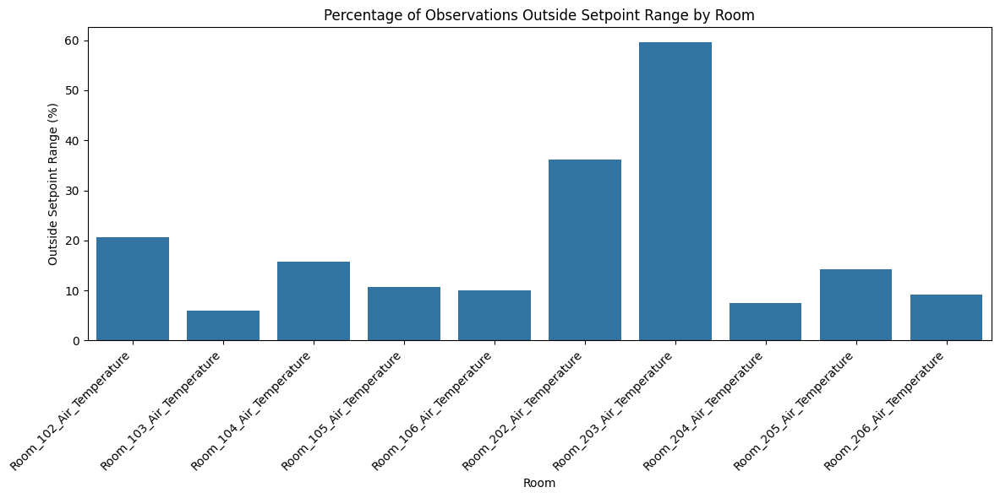

In [27]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=room_comfort_df,
    x="Room",
    y="Outside Comfort (%)"
)

plt.title("Percentage of Observations Outside Setpoint Range by Room")
plt.xlabel("Room")
plt.ylabel("Outside Setpoint Range (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [28]:
!pip -q install plotly ipywidgets

In [29]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display, HTML, clear_output
import ipywidgets as widgets

print("Dashboard libraries are ready!")

Dashboard libraries are ready!


In [34]:
from google.colab import output
output.enable_custom_widget_manager()

import plotly.io as pio
pio.renderers.default = "colab"

In [35]:
print("Dataset:", df.shape)

print("Temperature column:",
      "Average_Indoor_Temperature" in df.columns)

print("Comfort column:",
      "Outside_Comfort_Range" in df.columns)

print("HVAC electricity column:",
      "HVAC_System:_Electricity" in df.columns)

print("Room temperature columns:", len(room_temp_cols))

Dataset: (30240, 76)
Temperature column: True
Comfort column: True
HVAC electricity column: True
Room temperature columns: 10


In [36]:
# ============================================================
# HVAC ENERGY AND INDOOR COMFORT ANALYSIS DASHBOARD
# ============================================================

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as widgets

from IPython.display import display, HTML, clear_output
from google.colab import output

# Enable interactive widgets in Google Colab
output.enable_custom_widget_manager()

# Configure Plotly
import plotly.io as pio
pio.renderers.default = "colab"


# ============================================================
# 1. PREPARE DATA
# ============================================================

df = df.copy()

df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
df = df.dropna(subset=["Timestamp"]).sort_values("Timestamp")

room_temp_cols = [
    col for col in df.columns
    if col.startswith("Terminal:_Room_")
    and col.endswith("_Air_Temperature")
]

electricity_col = "HVAC_System:_Electricity"
supply_temp_col = "RTU:_Supply_Air_Temperature"
return_temp_col = "RTU:_Return_Air_Temperature"
fan_status_col = "RTU:_Supply_Air_Fan_Status"

# Recalculate indoor comfort metrics if necessary
if "Average_Indoor_Temperature" not in df.columns:
    df["Average_Indoor_Temperature"] = df[room_temp_cols].mean(axis=1)

heating_col = "Terminal:_Room_Air_Temperature_Heating_Setpoint"
cooling_col = "Terminal:_Room_Air_Temperature_Cooling_Setpoint"

if "Heating_Setpoint" not in df.columns:
    df["Heating_Setpoint"] = df[heating_col]

if "Cooling_Setpoint" not in df.columns:
    df["Cooling_Setpoint"] = df[cooling_col]

if "Comfort_Deviation" not in df.columns:
    df["Comfort_Deviation"] = np.maximum(
        df["Heating_Setpoint"] - df["Average_Indoor_Temperature"],
        df["Average_Indoor_Temperature"] - df["Cooling_Setpoint"]
    ).clip(lower=0)

if "Outside_Comfort_Range" not in df.columns:
    df["Outside_Comfort_Range"] = (
        (df["Average_Indoor_Temperature"] < df["Heating_Setpoint"]) |
        (df["Average_Indoor_Temperature"] > df["Cooling_Setpoint"])
    )

# Convert the date to a date-only column for filtering
df["Dashboard_Date"] = df["Timestamp"].dt.date

available_dates = sorted(df["Dashboard_Date"].dropna().unique())

if not available_dates:
    raise ValueError("No valid dates found in the dataset.")

room_names = {
    col: col.replace("Terminal:_Room_", "").replace("_Air_Temperature", "")
    for col in room_temp_cols
}


# ============================================================
# 2. CREATE FILTERS
# ============================================================

date_filter = widgets.SelectionRangeSlider(
    options=available_dates,
    index=(0, len(available_dates) - 1),
    description="Date Range:",
    orientation="horizontal",
    layout=widgets.Layout(width="85%"),
    style={"description_width": "100px"},
    continuous_update=False
)

room_filter = widgets.Dropdown(
    options=["All Rooms"] + [room_names[col] for col in room_temp_cols],
    value="All Rooms",
    description="Room:",
    layout=widgets.Layout(width="350px"),
    style={"description_width": "70px"}
)

refresh_button = widgets.Button(
    description="Update Dashboard",
    button_style="primary",
    icon="refresh",
    layout=widgets.Layout(width="200px")
)

dashboard_output = widgets.Output()


# ============================================================
# 3. DASHBOARD FUNCTION
# ============================================================

def create_dashboard(selected_dates, selected_room):

    start_date, end_date = selected_dates

    filtered = df[
        (df["Dashboard_Date"] >= start_date) &
        (df["Dashboard_Date"] <= end_date)
    ].copy()

    if filtered.empty:
        display(HTML("<h3>No data available for the selected dates.</h3>"))
        return

    # Keep only valid numeric measurements for charts
    valid_energy = filtered[electricity_col].dropna()

    avg_temp = filtered["Average_Indoor_Temperature"].mean()
    avg_deviation = filtered["Comfort_Deviation"].mean()

    outside_pct = (
        filtered["Outside_Comfort_Range"].mean() * 100
        if filtered["Outside_Comfort_Range"].notna().any()
        else np.nan
    )

    avg_hvac_electricity = valid_energy.mean() if not valid_energy.empty else np.nan

    # --------------------------------------------------------
    # KPI CARDS
    # --------------------------------------------------------

    def fmt(value, suffix=""):
        return f"{value:.2f}{suffix}" if pd.notna(value) else "N/A"

    cards = [
        ("Data Records", f"{len(filtered):,}"),
        ("Average Indoor Temperature", fmt(avg_temp, " °")),
        ("Average HVAC Electricity Reading", fmt(avg_hvac_electricity)),
        ("Outside Comfort Range", fmt(outside_pct, "%")),
        ("Average Comfort Deviation", fmt(avg_deviation, " °"))
    ]

    card_html = """
    <div style="
        display:flex;
        flex-wrap:wrap;
        gap:12px;
        margin:15px 0;
        font-family:Arial;
    ">
    """

    for title, value in cards:
        card_html += f"""
        <div style="
            flex:1;
            min-width:160px;
            padding:18px;
            border-radius:12px;
            background:#202938;
            color:white;
            text-align:center;
        ">
            <div style="font-size:13px;color:#cbd5e1;">
                {title}
            </div>
            <div style="
                font-size:23px;
                font-weight:bold;
                margin-top:10px;
                color:#38bdf8;
            ">
                {value}
            </div>
        </div>
        """

    card_html += "</div>"

    display(HTML(card_html))

    # Consistent dashboard styling
    chart_template = "plotly_dark"

    # --------------------------------------------------------
    # GRAPH 1: INDOOR TEMPERATURE AND SETPOINTS
    # --------------------------------------------------------

    temp_fig = go.Figure()

    temp_fig.add_trace(go.Scatter(
        x=filtered["Timestamp"],
        y=filtered["Average_Indoor_Temperature"],
        mode="lines",
        name="Average Indoor Temperature",
        line=dict(width=2)
    ))

    temp_fig.add_trace(go.Scatter(
        x=filtered["Timestamp"],
        y=filtered["Heating_Setpoint"],
        mode="lines",
        name="Heating Setpoint",
        line=dict(dash="dash")
    ))

    temp_fig.add_trace(go.Scatter(
        x=filtered["Timestamp"],
        y=filtered["Cooling_Setpoint"],
        mode="lines",
        name="Cooling Setpoint",
        line=dict(dash="dash")
    ))

    temp_fig.update_layout(
        title="1. Indoor Temperature vs Comfort Setpoints",
        xaxis_title="Timestamp",
        yaxis_title="Temperature (dataset units)",
        template=chart_template,
        height=430,
        hovermode="x unified"
    )

    display(temp_fig)


    # --------------------------------------------------------
    # GRAPH 2: HVAC ELECTRICITY OVER TIME
    # --------------------------------------------------------

    energy_data = filtered.dropna(
        subset=[electricity_col]
    )

    energy_fig = px.line(
        energy_data,
        x="Timestamp",
        y=electricity_col,
        title="2. HVAC Electricity Measurements Over Time",
        labels={
            "Timestamp": "Timestamp",
            electricity_col: "HVAC Electricity Reading"
        },
        template=chart_template
    )

    energy_fig.update_layout(
        height=430,
        hovermode="x unified"
    )

    display(energy_fig)


    # --------------------------------------------------------
    # GRAPH 3: ROOM-WISE TEMPERATURE COMPARISON
    # --------------------------------------------------------

    if selected_room == "All Rooms":
        selected_cols = room_temp_cols
    else:
        selected_cols = [
            col for col in room_temp_cols
            if room_names[col] == selected_room
        ]

    room_means = (
        filtered[selected_cols]
        .mean()
        .dropna()
        .reset_index()
    )

    room_means.columns = ["Room", "Average Temperature"]

    room_means["Room"] = (
        room_means["Room"]
        .str.replace("Terminal:_Room_", "", regex=False)
        .str.replace("_Air_Temperature", "", regex=False)
    )

    room_fig = px.bar(
        room_means,
        x="Room",
        y="Average Temperature",
        title="3. Average Temperature by Room",
        labels={
            "Room": "Room",
            "Average Temperature": "Average Temperature (dataset units)"
        },
        template=chart_template
    )

    room_fig.update_layout(height=430)

    display(room_fig)


    # --------------------------------------------------------
    # GRAPH 4: HVAC ELECTRICITY VS RETURN AIR TEMPERATURE
    # --------------------------------------------------------

    scatter_data = filtered[
        [return_temp_col, electricity_col]
    ].dropna()

    scatter_fig = px.scatter(
        scatter_data,
        x=return_temp_col,
        y=electricity_col,
        title="4. HVAC Electricity vs Return Air Temperature",
        labels={
            return_temp_col: "Return Air Temperature",
            electricity_col: "HVAC Electricity Reading"
        },
        opacity=0.6,
        template=chart_template
    )

    scatter_fig.update_layout(height=430)

    display(scatter_fig)


    # --------------------------------------------------------
    # GRAPH 5: HVAC FAN AND COMPRESSOR STATUS
    # --------------------------------------------------------

    status_cols = [
        col for col in [
            fan_status_col,
            "RTU:_Compressor_1_On/Off_Status",
            "RTU:_Compressor_2_On/Off_Status"
        ]
        if col in filtered.columns
    ]

    if status_cols:

        status_data = filtered[status_cols].copy()

        status_data = status_data.rename(columns={
            fan_status_col: "Supply Air Fan",
            "RTU:_Compressor_1_On/Off_Status": "Compressor 1",
            "RTU:_Compressor_2_On/Off_Status": "Compressor 2"
        })

        status_data["Timestamp"] = filtered["Timestamp"]

        # Plot a manageable number of points while retaining
        # the temporal pattern across the selected period.
        max_points = 2000

        if len(status_data) > max_points:
            step = int(np.ceil(len(status_data) / max_points))
            status_data = status_data.iloc[::step]

        status_fig = go.Figure()

        for col in status_data.columns:
            if col != "Timestamp":
                status_fig.add_trace(go.Scatter(
                    x=status_data["Timestamp"],
                    y=status_data[col],
                    mode="lines",
                    name=col
                ))

        status_fig.update_layout(
            title="5. HVAC Fan and Compressor Operating Status",
            xaxis_title="Timestamp",
            yaxis_title="Status (0 = OFF, 1 = ON)",
            template=chart_template,
            height=430,
            hovermode="x unified"
        )

        display(status_fig)

    # --------------------------------------------------------
    # SUMMARY INSIGHTS
    # --------------------------------------------------------

    outside_count = filtered["Outside_Comfort_Range"].sum()
    total_valid = filtered["Outside_Comfort_Range"].notna().sum()

    if total_valid > 0:
        outside_pct_text = f"{outside_pct:.2f}%"
    else:
        outside_pct_text = "Unavailable"

    insights_html = f"""
    <div style="
        background:#202938;
        color:white;
        padding:20px;
        border-radius:12px;
        margin-top:15px;
        font-family:Arial;
    ">
        <h3 style="color:#38bdf8;">Dashboard Insights</h3>
        <ul>
            <li>Average indoor temperature:
                <b>{fmt(avg_temp, " °")}</b>
            </li>
            <li>Average HVAC electricity reading:
                <b>{fmt(avg_hvac_electricity)}</b>
            </li>
            <li>Observations outside the configured comfort range:
                <b>{outside_pct_text}</b>
            </li>
            <li>Number of observations outside the comfort range:
                <b>{int(outside_count):,}</b>
            </li>
        </ul>
        <p>
            Use the temperature and setpoint graph to identify periods
            when indoor conditions fall outside the configured range.
            Compare the electricity and equipment-status graphs to
            investigate possible relationships between HVAC operation
            and electricity measurements.
        </p>
        <p style="color:#cbd5e1;font-size:12px;">
            Note: Electricity readings are displayed in the dataset's
            recorded units. They should not be interpreted as kWh
            without confirming the dataset's measurement definitions.
        </p>
    </div>
    """

    display(HTML(insights_html))


# ============================================================
# 4. UPDATE FUNCTION
# ============================================================

def update_dashboard(change=None):

    with dashboard_output:
        clear_output(wait=True)

        try:
            create_dashboard(
                date_filter.value,
                room_filter.value
            )

        except Exception as e:
            print("Dashboard Error:", repr(e))


# ============================================================
# 5. CONNECT FILTERS AND DISPLAY DASHBOARD
# ============================================================

refresh_button.on_click(update_dashboard)

controls = widgets.VBox([
    widgets.HTML("""
        <h2 style="font-family:Arial;">
            HVAC Energy and Indoor Comfort Dashboard
        </h2>
        <p style="font-family:Arial;">
            Analyze HVAC electricity measurements, indoor temperatures,
            comfort setpoints, and equipment operation.
        </p>
    """),
    date_filter,
    room_filter,
    refresh_button
])

display(controls)
display(dashboard_output)

# Automatically render the initial dashboard
update_dashboard()

Output()

In [33]:
import plotly.express as px

fig = px.line(
    df.head(200),
    x="Timestamp",
    y="HVAC_System:_Electricity",
    title="HVAC Electricity Measurements"
)

fig.show()

In [37]:
# ============================================================
# HVAC ENERGY AND INDOOR COMFORT ANALYSIS
# Five Interactive Graphs
# ============================================================

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

# Enable Plotly in Google Colab
import plotly.io as pio
pio.renderers.default = "colab"

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

data = df.copy()

data["Timestamp"] = pd.to_datetime(
    data["Timestamp"], errors="coerce"
)

data = data.dropna(subset=["Timestamp"]).sort_values("Timestamp")

room_temp_cols = [
    col for col in data.columns
    if col.startswith("Terminal:_Room_")
    and col.endswith("_Air_Temperature")
]

energy_col = "HVAC_System:_Electricity"
return_col = "RTU:_Return_Air_Temperature"

heating_col = "Terminal:_Room_Air_Temperature_Heating_Setpoint"
cooling_col = "Terminal:_Room_Air_Temperature_Cooling_Setpoint"

# Calculate indoor temperature if not already available
if "Average_Indoor_Temperature" not in data.columns:
    data["Average_Indoor_Temperature"] = (
        data[room_temp_cols].mean(axis=1)
    )

# Calculate comfort range if the columns are available
if heating_col in data.columns and cooling_col in data.columns:

    data["Heating_Setpoint"] = data[heating_col]
    data["Cooling_Setpoint"] = data[cooling_col]

    data["Outside_Comfort_Range"] = (
        (data["Average_Indoor_Temperature"] < data[heating_col]) |
        (data["Average_Indoor_Temperature"] > data[cooling_col])
    )

print("Dataset prepared successfully.")
print("Number of records:", len(data))
print("Number of rooms:", len(room_temp_cols))


# ------------------------------------------------------------
# GRAPH 1: INDOOR TEMPERATURE VS SETPOINTS
# ------------------------------------------------------------

print("Displaying Graph 1...")

fig1 = go.Figure()

fig1.add_trace(go.Scatter(
    x=data["Timestamp"],
    y=data["Average_Indoor_Temperature"],
    mode="lines",
    name="Average Indoor Temperature"
))

if "Heating_Setpoint" in data.columns:
    fig1.add_trace(go.Scatter(
        x=data["Timestamp"],
        y=data["Heating_Setpoint"],
        mode="lines",
        name="Heating Setpoint",
        line=dict(dash="dash")
    ))

if "Cooling_Setpoint" in data.columns:
    fig1.add_trace(go.Scatter(
        x=data["Timestamp"],
        y=data["Cooling_Setpoint"],
        mode="lines",
        name="Cooling Setpoint",
        line=dict(dash="dash")
    ))

fig1.update_layout(
    title="1. Indoor Temperature vs Comfort Setpoints",
    xaxis_title="Timestamp",
    yaxis_title="Temperature (dataset units)",
    template="plotly_dark",
    height=450
)

display(fig1)


# ------------------------------------------------------------
# GRAPH 2: HVAC ELECTRICITY OVER TIME
# ------------------------------------------------------------

print("Displaying Graph 2...")

fig2 = px.line(
    data,
    x="Timestamp",
    y=energy_col,
    title="2. HVAC Electricity Measurements Over Time",
    template="plotly_dark"
)

fig2.update_layout(
    xaxis_title="Timestamp",
    yaxis_title="HVAC Electricity Reading",
    height=450
)

display(fig2)


# ------------------------------------------------------------
# GRAPH 3: ROOM-WISE TEMPERATURE COMPARISON
# ------------------------------------------------------------

print("Displaying Graph 3...")

room_data = (
    data[room_temp_cols]
    .mean()
    .dropna()
    .reset_index()
)

room_data.columns = ["Room", "Average Temperature"]

room_data["Room"] = (
    room_data["Room"]
    .str.replace("Terminal:_Room_", "", regex=False)
    .str.replace("_Air_Temperature", "", regex=False)
)

fig3 = px.bar(
    room_data,
    x="Room",
    y="Average Temperature",
    title="3. Average Indoor Temperature by Room",
    template="plotly_dark"
)

fig3.update_layout(
    xaxis_title="Room",
    yaxis_title="Average Temperature (dataset units)",
    height=450
)

display(fig3)


# ------------------------------------------------------------
# GRAPH 4: ELECTRICITY VS RETURN AIR TEMPERATURE
# ------------------------------------------------------------

print("Displaying Graph 4...")

scatter_data = data[
    [return_col, energy_col]
].dropna()

fig4 = px.scatter(
    scatter_data,
    x=return_col,
    y=energy_col,
    title="4. HVAC Electricity vs Return Air Temperature",
    opacity=0.5,
    template="plotly_dark"
)

fig4.update_layout(
    xaxis_title="Return Air Temperature",
    yaxis_title="HVAC Electricity Reading",
    height=450
)

display(fig4)


# ------------------------------------------------------------
# GRAPH 5: HVAC FAN AND COMPRESSOR STATUS
# ------------------------------------------------------------

print("Displaying Graph 5...")

status_cols = [
    col for col in [
        "RTU:_Supply_Air_Fan_Status",
        "RTU:_Compressor_1_On/Off_Status",
        "RTU:_Compressor_2_On/Off_Status"
    ]
    if col in data.columns
]

fig5 = go.Figure()

for col in status_cols:
    fig5.add_trace(go.Scatter(
        x=data["Timestamp"],
        y=data[col],
        mode="lines",
        name=col.replace("RTU:_", "").replace("_On/Off_Status", "")
    ))

fig5.update_layout(
    title="5. HVAC Fan and Compressor Operating Status",
    xaxis_title="Timestamp",
    yaxis_title="Status (0 = OFF, 1 = ON)",
    template="plotly_dark",
    height=450
)

display(fig5)

print("All five graphs have been generated.")

Dataset prepared successfully.
Number of records: 30240
Number of rooms: 10
Displaying Graph 1...


Displaying Graph 2...


Displaying Graph 3...


Displaying Graph 4...


Displaying Graph 5...


All five graphs have been generated.
